# 03 — Gold Layer

**Input:**
- `silver-master / master_df` — 32M dòng giao dịch thực tế
- `silver-features / clustering_scaled` — vector đã scale cho KMeans
- `silver-features / similarity_scaled` — vector đã scale cho FAISS
- `silver-features / user_features_df` — raw features 206k users

**Output (9 bảng Gold → Power BI):**

| Bảng | Dòng | Vai trò |
|---|---|---|
| `dim_user` | 206k | PK user, cluster FK, KPI metrics |
| `dim_cluster` | 6 | Profile trung bình từng cluster |
| `dim_product` | 50k | Tên + department sản phẩm |
| `dim_time_behavior` | 168 | Lookup giờ × ngày |
| `fact_product_stats` | ~50k | order_count + reorder_count per product |
| `fact_cluster_dept` | 126 | order_count per cluster × department |
| `ml_top_recommendations` | 60 | TF-IDF  top-10 per cluster |
| `association_rules` | ~60 | FP-Growth rules department level |
| `kmeans_scores` | 10 | Elbow + Silhouette + final metrics |


In [1]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import os
os.environ["PYTHONWARNINGS"] = "ignore::DeprecationWarning"


In [2]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [3]:
# Cell 1 — Cài thư viện + clone repo
!pip install supabase scikit-learn faiss-cpu mlxtend -q

import os, shutil, subprocess, sys

REPO_PATH = "/kaggle/working/repo"
if os.path.exists(REPO_PATH):
    shutil.rmtree(REPO_PATH)

subprocess.run([
    "git", "clone",
    "https://github.com/rhyni/retail-recommender-system.git",
    REPO_PATH
], check=True)

sys.path.insert(0, REPO_PATH)
print("✓ Repo đã clone xong")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 59.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 730.3/730.3 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 6.4 MB/s eta 0:00:00


Cloning into '/kaggle/working/repo'...


✓ Repo đã clone xong


In [4]:
# Cell 2 — Load Secrets + config
from kaggle_secrets import UserSecretsClient
from src import config

secrets = UserSecretsClient()
config.SUPABASE_URL = secrets.get_secret("SUPABASE_URL")
config.SUPABASE_KEY = secrets.get_secret("SUPABASE_KEY")

print("✓ Supabase config loaded")
print("SILVER_BUCKET:", config.SILVER_BUCKET)
print("GOLD_BUCKET  :", config.GOLD_BUCKET)
print("GOLD_PREFIX  :", config.GOLD_PREFIX)


✓ Supabase config loaded
SILVER_BUCKET: silver-data
GOLD_BUCKET  : gold-data
GOLD_PREFIX  : instacart/gold


In [5]:
# Cell 3 — Khai báo RUN_IDs
from datetime import datetime, timezone

GOLD_RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

# TODO: copy từ output 02a và 02b
SILVER_MASTER_RUN_ID   = "20260424T065124Z"
SILVER_FEATURES_RUN_ID = "20260424T071558Z"

SILVER_MASTER_PREFIX   = "instacart/silver-master"
SILVER_FEATURES_PREFIX = "instacart/silver-features"

print(f"SILVER_MASTER_RUN_ID   : {SILVER_MASTER_RUN_ID}")
print(f"SILVER_FEATURES_RUN_ID : {SILVER_FEATURES_RUN_ID}")
print(f"GOLD_RUN_ID            : {GOLD_RUN_ID}")


SILVER_MASTER_RUN_ID   : 20260424T065124Z
SILVER_FEATURES_RUN_ID : 20260424T071558Z
GOLD_RUN_ID            : 20260512T133347Z


In [6]:
# Cell 4 — Load Silver tables
import pandas as pd
import numpy as np
from src.io_utils import load_dataframe

print("Loading Silver Features...")
clustering_scaled = load_dataframe(config.SILVER_BUCKET, SILVER_FEATURES_PREFIX, SILVER_FEATURES_RUN_ID, "clustering_scaled")
similarity_scaled = load_dataframe(config.SILVER_BUCKET, SILVER_FEATURES_PREFIX, SILVER_FEATURES_RUN_ID, "similarity_scaled")
user_features_df  = load_dataframe(config.SILVER_BUCKET, SILVER_FEATURES_PREFIX, SILVER_FEATURES_RUN_ID, "user_features_df")

print("Loading Silver Master...")
master_df = load_dataframe(config.SILVER_BUCKET, SILVER_MASTER_PREFIX, SILVER_MASTER_RUN_ID, "master_df")

print(f"\n✓ clustering_scaled : {clustering_scaled.shape}")
print(f"✓ similarity_scaled : {similarity_scaled.shape}")
print(f"✓ user_features_df  : {user_features_df.shape}")
print(f"✓ master_df         : {master_df.shape}")


Loading Silver Features...
  ✓ loaded [clustering_scaled]: 1 file | 206,209 rows
  ✓ loaded [similarity_scaled]: 1 file | 206,209 rows
  ✓ loaded [user_features_df]: 1 file | 206,209 rows
Loading Silver Master...
  ✓ loaded [master_df]: 65 chunks | 32,434,489 rows

✓ clustering_scaled : (206209, 15)
✓ similarity_scaled : (206209, 14)
✓ user_features_df  : (206209, 25)
✓ master_df         : (32434489, 16)


# PHẦN 1 — KMeans Clustering

⚠️  kneed chưa cài — elbow sẽ dùng diff thủ công. Chạy: !pip install kneed -q
Running Elbow + Silhouette (K = 2 → 15)...
  K= 2 | inertia=   2,325,960 | silhouette=0.1780
  K= 3 | inertia=   2,031,934 | silhouette=0.1513
  K= 4 | inertia=   1,869,162 | silhouette=0.1332
  K= 5 | inertia=   1,722,956 | silhouette=0.1393
  K= 6 | inertia=   1,637,842 | silhouette=0.1334
  K= 7 | inertia=   1,565,052 | silhouette=0.1272
  K= 8 | inertia=   1,504,450 | silhouette=0.1230
  K= 9 | inertia=   1,456,178 | silhouette=0.1229
  K=10 | inertia=   1,410,692 | silhouette=0.1132
  K=11 | inertia=   1,370,467 | silhouette=0.1111
  K=12 | inertia=   1,336,887 | silhouette=0.1071
  K=13 | inertia=   1,306,855 | silhouette=0.1060
  K=14 | inertia=   1,280,908 | silhouette=0.1043
  K=15 | inertia=   1,257,734 | silhouette=0.1051

📊 Elbow point        : K=3
📊 Silhouette peak    : K=2  (score=0.1780)
✅ BEST_K chọn        : K=5
   ↳ Điều chỉnh từ K=2 lên K=5 theo business constraint (≥4 segment)


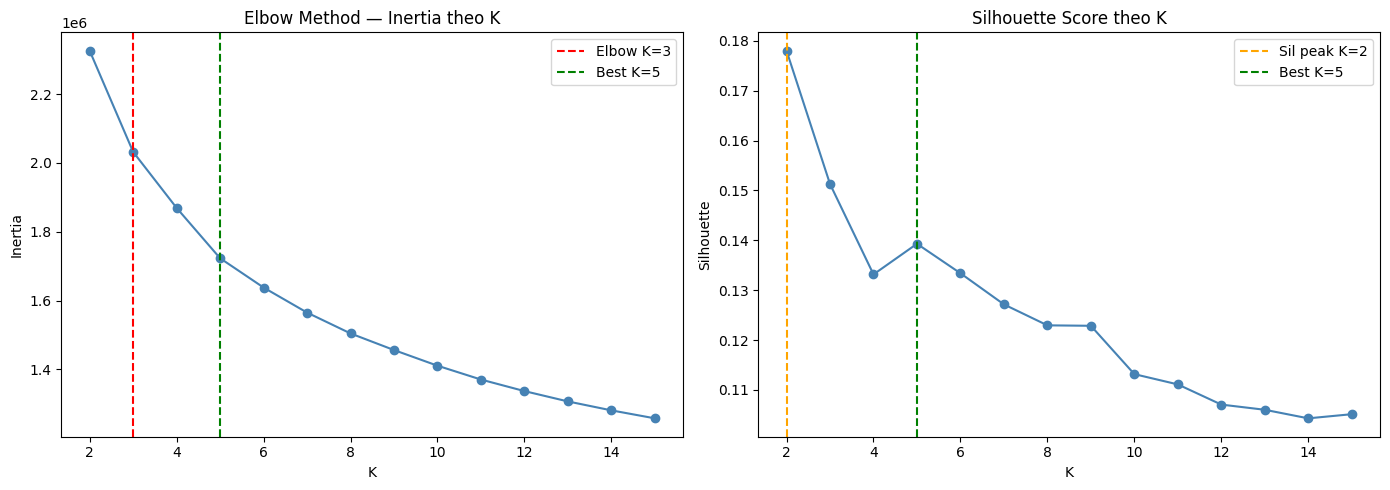

In [7]:
# Cell 5 — Elbow + Silhouette → chọn K tối ưu  (K = 2 → 15)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
 
try:
    from kneed import KneeLocator
    HAS_KNEED = True
except ImportError:
    HAS_KNEED = False
    print("⚠️  kneed chưa cài — elbow sẽ dùng diff thủ công. Chạy: !pip install kneed -q")
 
feature_cols = [c for c in clustering_scaled.columns if c != "user_id"]
X_cluster    = clustering_scaled[feature_cols].values.astype("float32")
 
inertia_scores    = {}
silhouette_scores = {}
 
print("Running Elbow + Silhouette (K = 2 → 15)...")
for k in range(2, 16):
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
 
    sil = silhouette_score(
        X_cluster, labels,
        sample_size=min(50_000, len(X_cluster)),
        random_state=42
    )
    inertia_scores[k]    = km.inertia_
    silhouette_scores[k] = sil
    print(f"  K={k:2d} | inertia={km.inertia_:>12,.0f} | silhouette={sil:.4f}")
 
# ── Tìm elbow point ──────────────────────────────────────────
ks      = list(inertia_scores.keys())
inertia = list(inertia_scores.values())
 
if HAS_KNEED:
    kl        = KneeLocator(ks, inertia, curve="convex", direction="decreasing")
    ELBOW_K   = kl.knee or ks[0]
else:
    # Diff thủ công: tìm điểm giảm chậm nhất
    diffs     = [inertia[i] - inertia[i+1] for i in range(len(inertia)-1)]
    ratios    = [diffs[i] / diffs[i+1] if diffs[i+1] != 0 else 0 for i in range(len(diffs)-1)]
    ELBOW_K   = ks[ratios.index(max(ratios)) + 1]
 
# ── Chọn BEST_K theo silhouette, nhưng không nhỏ hơn 4 (business sense) ──
BEST_K_SIL = max(silhouette_scores, key=silhouette_scores.get)
BEST_K = 5 
print(f"\n📊 Elbow point        : K={ELBOW_K}")
print(f"📊 Silhouette peak    : K={BEST_K_SIL}  (score={silhouette_scores[BEST_K_SIL]:.4f})")
print(f"✅ BEST_K chọn        : K={BEST_K}")
if BEST_K != BEST_K_SIL:
    print(f"   ↳ Điều chỉnh từ K={BEST_K_SIL} lên K={BEST_K} theo business constraint (≥4 segment)")
 
# ── Plot ─────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
 
ax1.plot(ks, inertia, "o-", color="steelblue")
ax1.axvline(ELBOW_K, color="red",    linestyle="--", label=f"Elbow K={ELBOW_K}")
ax1.axvline(BEST_K,  color="green",  linestyle="--", label=f"Best K={BEST_K}")
ax1.set_title("Elbow Method — Inertia theo K")
ax1.set_xlabel("K"); ax1.set_ylabel("Inertia")
ax1.legend()
 
sil_vals = [silhouette_scores[k] for k in ks]
ax2.plot(ks, sil_vals, "o-", color="steelblue")
ax2.axvline(BEST_K_SIL, color="orange", linestyle="--", label=f"Sil peak K={BEST_K_SIL}")
ax2.axvline(BEST_K,     color="green",  linestyle="--", label=f"Best K={BEST_K}")
ax2.set_title("Silhouette Score theo K")
ax2.set_xlabel("K"); ax2.set_ylabel("Silhouette")
ax2.legend()
 
plt.tight_layout()
plt.show()
 
# ── kmeans_scores_df ─────────────────────────────────────────
kmeans_scores_df = pd.DataFrame({
    "k":                    ks,
    "inertia":              inertia,
    "silhouette_score":     sil_vals,
    "silhouette_final":     None,
    "davies_bouldin_final": None,
})

In [8]:
# Cell 6 — Fit KMeans với BEST_K → gán cluster_id
km_final       = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
cluster_labels = km_final.fit_predict(X_cluster)
 
user_cluster                = clustering_scaled[["user_id"]].copy()
user_cluster["cluster_id"]  = cluster_labels.astype("int16")
 
clustering_scaled = (
    clustering_scaled.drop(columns=["cluster_id"], errors="ignore")
    .merge(user_cluster, on="user_id", how="left")
    .sort_values("user_id")
    .reset_index(drop=True)
)
 
assert clustering_scaled["cluster_id"].nunique() == BEST_K, \
    f"❌ Số cluster thực tế ({clustering_scaled['cluster_id'].nunique()}) ≠ BEST_K ({BEST_K})"
assert clustering_scaled["user_id"].nunique() == len(clustering_scaled), \
    "❌ Duplicate user_id trong clustering_scaled"
 
print(f"✓ Đã gán cluster_id cho {len(clustering_scaled):,} users | K={BEST_K}")
print(clustering_scaled["cluster_id"].value_counts().sort_index())

✓ Đã gán cluster_id cho 206,209 users | K=5
cluster_id
0    54020
1    67248
2    26858
3    33321
4    24762
Name: count, dtype: int64


In [9]:
# # Chạy debug này trước để xem score thực tế
# print("=== GLOBAL_MEDIAN ===")
# for k, v in GLOBAL_MEDIAN.items():
#     print(f"  {k}: {v:.3f}")

# print("\n=== SCORE từng cluster ===")
# for _, row in cluster_profile.iterrows():
#     scores = score_archetypes(row)
#     print(f"\nCluster {int(row['cluster_id'])}:")
#     print(f"  days={row['avg_days_between_orders']:.3f}, basket={row['avg_basket_size']:.3f}, "
#           f"reorder={row['reorder_rate']:.3f}")
#     for label, score in sorted(scores.items(), key=lambda x: -x[1]):
#         print(f"  {score:.4f} → {label}")

In [10]:
# Cell 7 — Cluster profile → assign_label → dim_cluster
feature_cluster_df = user_features_df.merge(user_cluster, on="user_id", how="left")

GLOBAL_MEDIAN = {
    col: float(user_features_df[col].median()) if col in user_features_df.columns else 0.0
    for col in ["total_orders", "avg_basket_size", "reorder_rate",
                "avg_days_between_orders", "pct_weekend_orders"]
}

agg_dict = {"user_count": ("user_id", "nunique")}
for col in ["total_orders", "avg_basket_size", "reorder_rate",
            "avg_days_between_orders", "pct_weekend_orders"]:
    if col in feature_cluster_df.columns:
        agg_dict[col] = (col, "mean")

cluster_profile = (
    feature_cluster_df
    .groupby("cluster_id")
    .agg(**agg_dict)
    .round(3)
    .reset_index()
)

# ── Hardcode label dựa trên profile thực tế ─────────────────
# Thứ tự if-elif quan trọng: check đặc trưng CỰC ĐOAN trước
def assign_label(row):
    days    = row["avg_days_between_orders"]
    basket  = row["avg_basket_size"]
    reorder = row["reorder_rate"]

    if basket < 4:           # Cluster 2: basket=2.9 — thấp tuyệt đối
        return "Low Engagement"
    elif basket > 15:        # Cluster 3: basket=19.4 — cao tuyệt đối
        return "Bulk Buyer"
    elif reorder > 0.6 and days < 8:   # Cluster 4: reorder=0.704 + days=6.7
        return "Loyal High-frequency Buyer"
    elif days < 13:          # Cluster 1: days=11.5
        return "High-frequency Buyer"
    else:                    # Cluster 0: days=22.3
        return "Occasional Buyer"

cluster_profile["cluster_label"] = cluster_profile.apply(assign_label, axis=1)

# ── Verify không collision ───────────────────────────────────
print("=== Cluster profile ===")
for _, row in cluster_profile.iterrows():
    print(f"  Cluster {int(row['cluster_id'])} → {row['cluster_label']:<30} "
          f"| basket={row['avg_basket_size']:.1f} "
          f"| reorder={row['reorder_rate']:.3f} "
          f"| days={row['avg_days_between_orders']:.1f}")

assert cluster_profile["cluster_label"].nunique() == len(cluster_profile), \
    f"❌ Duplicate label: {cluster_profile['cluster_label'].tolist()}"

# ── dim_cluster ──────────────────────────────────────────────
dim_cluster = cluster_profile[[
    "cluster_id", "cluster_label", "user_count",
    "avg_basket_size", "reorder_rate",
    "avg_days_between_orders", "pct_weekend_orders"
]].copy()

print(f"\n✓ dim_cluster: {dim_cluster.shape}")
print(dim_cluster[["cluster_id", "cluster_label", "user_count"]].to_string(index=False))
print(f"\n  Label unique: {dim_cluster['cluster_label'].nunique()} / {len(dim_cluster)} ✅")

=== Cluster profile ===
  Cluster 0 → Occasional Buyer               | basket=9.2 | reorder=0.261 | days=22.3
  Cluster 1 → High-frequency Buyer           | basket=8.5 | reorder=0.452 | days=11.5
  Cluster 2 → Low Engagement                 | basket=2.9 | reorder=0.426 | days=17.8
  Cluster 3 → Bulk Buyer                     | basket=19.4 | reorder=0.474 | days=15.5
  Cluster 4 → Loyal High-frequency Buyer     | basket=10.3 | reorder=0.704 | days=6.7

✓ dim_cluster: (5, 7)
 cluster_id              cluster_label  user_count
          0           Occasional Buyer       54020
          1       High-frequency Buyer       67248
          2             Low Engagement       26858
          3                 Bulk Buyer       33321
          4 Loyal High-frequency Buyer       24762

  Label unique: 5 / 5 ✅


In [11]:
# Cell 8 — dim_user
# 
base_user_cols = ["user_id", "total_orders", "avg_basket_size", "reorder_rate"]
base_user_cols = [c for c in base_user_cols if c in user_features_df.columns]
 
dim_user = (
    user_features_df[base_user_cols]
    .merge(user_cluster[["user_id", "cluster_id"]], on="user_id", how="left")
)
dim_user = dim_user[["user_id", "cluster_id"] + [c for c in base_user_cols if c != "user_id"]]
 
assert dim_user["user_id"].nunique() == len(dim_user),   "❌ Duplicate user_id trong dim_user"
assert dim_user["cluster_id"].notna().all(),              "❌ Có user thiếu cluster_id"
assert dim_user["cluster_id"].isin(dim_cluster["cluster_id"]).all(), \
    "❌ cluster_id trong dim_user không khớp dim_cluster"
 
print(f"✓ dim_user: {dim_user.shape}")
print(f"  Columns: {list(dim_user.columns)}")
dim_user.head(10)

✓ dim_user: (206209, 5)
  Columns: ['user_id', 'cluster_id', 'total_orders', 'avg_basket_size', 'reorder_rate']


,user_id,cluster_id,total_orders,avg_basket_size,reorder_rate
0,1,2,10,5.900000,0.694915
1,2,3,14,13.928572,0.476923
2,3,1,12,7.333333,0.625000
3,4,2,5,3.600000,0.055556
4,5,1,4,9.250000,0.378378
5,6,1,3,4.666667,0.142857
6,7,1,20,10.300000,0.669903
7,8,0,3,16.333334,0.265306
8,9,3,3,25.333334,0.236842
9,10,3,5,28.600000,0.342657


# PHẦN 2 — Recommendation 

In [12]:
# PHẦN 2 — Recommendation dùng TF-IDF trên cluster

import numpy as np

# ── Bước 1: Tần suất mua per cluster × product (TF) ─────────
user_product_history = (
    master_df[["user_id", "product_id", "product_name", "department", "order_id"]]
    .dropna()
    .groupby(["user_id", "product_id"])
    .agg(
        purchase_freq = ("order_id",     "count"),
        product_name  = ("product_name", "first"),
        department    = ("department",   "first"),
    )
    .reset_index()
    .merge(user_cluster, on="user_id", how="inner")
)

# Tần suất mua của từng sản phẩm trong từng cluster
cluster_product_tf = (
    user_product_history
    .groupby(["cluster_id", "product_id", "product_name", "department"])
    .agg(
        cluster_freq  = ("purchase_freq", "sum"),   # tổng lần mua trong cluster
        buyer_count   = ("user_id",       "nunique") # số user trong cluster mua sp này
    )
    .reset_index()
)

# Normalize TF theo số user trong cluster → tránh cluster lớn luôn thắng
cluster_size = user_cluster.groupby("cluster_id")["user_id"].nunique().reset_index()
cluster_size.columns = ["cluster_id", "cluster_size"]

cluster_product_tf = cluster_product_tf.merge(cluster_size, on="cluster_id")
cluster_product_tf["tf"] = (
    cluster_product_tf["cluster_freq"] /
    cluster_product_tf["cluster_size"]
)

# ── Bước 2: IDF — sản phẩm xuất hiện ở bao nhiêu cluster ────
n_clusters = cluster_product_tf["cluster_id"].nunique()

product_cluster_count = (
    cluster_product_tf
    .groupby("product_id")["cluster_id"]
    .nunique()
    .reset_index()
    .rename(columns={"cluster_id": "n_clusters_with_product"})
)

product_cluster_count["idf"] = np.log(
    n_clusters / (product_cluster_count["n_clusters_with_product"] + 1e-9)
)

# ── Bước 3: TF-IDF score ─────────────────────────────────────
cluster_product_tf = cluster_product_tf.merge(
    product_cluster_count[["product_id", "idf"]], on="product_id"
)
cluster_product_tf["tfidf_score"] = (
    cluster_product_tf["tf"] * cluster_product_tf["idf"]
)

# ── Bước 4: Top-10 per cluster ───────────────────────────────
recommendations = []

for cid in sorted(cluster_product_tf["cluster_id"].unique()):
    cluster_df = cluster_product_tf[cluster_product_tf["cluster_id"] == cid].copy()

    # Normalize score về [0, 1]
    cluster_df["final_score"] = (
        cluster_df["tfidf_score"] /
        (cluster_df["tfidf_score"].max() + 1e-9)
    ).clip(0, 1).round(4).astype("float32")

    top10 = (
        cluster_df
        .sort_values("final_score", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )
    top10["cluster_id"] = int(cid)
    top10["rank"]       = range(1, len(top10) + 1)
    recommendations.append(top10)

    label = dim_cluster[dim_cluster["cluster_id"] == cid]["cluster_label"].values[0]
    top3  = top10.head(3)["product_name"].tolist()
    print(f"✓ Cluster {cid} ({label}): {top3}")

# ── Bước 5: Tạo ml_top_recommendations ──────────────────────
rec_raw = pd.concat(recommendations, ignore_index=True)

ml_top_recommendations = (
    rec_raw
    .merge(dim_cluster[["cluster_id", "cluster_label"]], on="cluster_id", how="left")
    [["cluster_id", "cluster_label", "rank", "product_name", "department", "final_score"]]
)

assert ml_top_recommendations["cluster_id"].nunique() == BEST_K
assert len(ml_top_recommendations) <= BEST_K * 10

✓ Cluster 0 (Occasional Buyer): ['Carrot Chips', 'Organic Soba', 'Organic Diced Fire Roasted Tomatoes']
✓ Cluster 1 (High-frequency Buyer): ['Organic Diced Fire Roasted Tomatoes', 'Traditional Scottish Style Smoked Salmon', 'Organic Whole Wheat Elbows']
✓ Cluster 2 (Low Engagement): ['Variety of Anitoxidant Infusions Cans', 'Foil Sheets', 'Organic Lowafat 1% Milk']
✓ Cluster 3 (Bulk Buyer): ['Organic Whole Wheat Elbows', 'Fiber & Protein Organic Pears, Raspberries, Butternut Squash & Carrots Snack', 'Organic Soba']
✓ Cluster 4 (Loyal High-frequency Buyer): ['Organic Whole Wheat Elbows', 'Organic Soba', 'Organic Baby Food Banana Beet & Blueberry']


In [13]:
print(f"\n✓ ml_top_recommendations: {ml_top_recommendations.shape}")
ml_top_recommendations.head(50)


✓ ml_top_recommendations: (50, 6)


,cluster_id,cluster_label,rank,product_name,department,final_score
0,0,Occasional Buyer,1,Carrot Chips,produce,1.0000
1,0,Occasional Buyer,2,Organic Soba,international,0.8903
2,0,Occasional Buyer,3,Organic Diced Fire Roasted Tomatoes,canned goods,0.8816
3,0,Occasional Buyer,4,Organic Whole Wheat Elbows,dry goods pasta,0.7895
4,0,Occasional Buyer,5,Quinoa,dry goods pasta,0.6667
5,0,Occasional Buyer,6,Cinnamon Applesauce,canned goods,0.6360
6,0,Occasional Buyer,7,Tikka Masala Simmer Sauce,international,0.6316
7,0,Occasional Buyer,8,Traditional Scottish Style Smoked Salmon,meat seafood,0.6053
8,0,Occasional Buyer,9,Organic Tomato Puree,canned goods,0.5789
9,0,Occasional Buyer,10,Light Tuna Chunk In Water,canned goods,0.5789


In [14]:
# Xem đúng cột có trong dim_cluster
print(dim_cluster.columns.tolist())
print()
print(dim_cluster.to_string(index=False))

['cluster_id', 'cluster_label', 'user_count', 'avg_basket_size', 'reorder_rate', 'avg_days_between_orders', 'pct_weekend_orders']

 cluster_id              cluster_label  user_count  avg_basket_size  reorder_rate  avg_days_between_orders  pct_weekend_orders
          0           Occasional Buyer       54020         9.232000         0.261                   22.306               0.386
          1       High-frequency Buyer       67248         8.532000         0.452                   11.472               0.333
          2             Low Engagement       26858         2.949000         0.426                   17.750               0.299
          3                 Bulk Buyer       33321        19.400999         0.474                   15.503               0.406
          4 Loyal High-frequency Buyer       24762        10.256000         0.704                    6.729               0.338


# PHẦN 3 — Association Rules (FP-Growth)

In [15]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [16]:
# PHẦN 3 — Association Rules (FP-Growth)
# Nhiệm vụ: Tìm các quy tắc kết hợp department-level
# "Khách mua department A thường mua kèm department B"
 
 # Cell 11 — Tạo transaction matrix department-level
import warnings
warnings.filterwarnings("ignore")
import logging
logging.getLogger("jupyter_client").setLevel(logging.ERROR)
 
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
 
# Mỗi order → list các department đã mua (unique, sorted)
transactions = (
    master_df[["order_id", "department"]]
    .dropna(subset=["order_id", "department"])
    .groupby("order_id")["department"]
    .apply(lambda x: sorted(set(x)))
    .tolist()
)
 
te     = TransactionEncoder()
te_arr = te.fit_transform(transactions)
dept_df = pd.DataFrame(te_arr, columns=te.columns_)
 
# ── Kiểm tra sample rate để quyết định có cần sample không ──
total_orders = len(dept_df)
MAX_ROWS     = 100_000
sample_rate  = min(MAX_ROWS, total_orders) / total_orders * 100
 
print(f"✓ Tổng transactions : {total_orders:,}")
print(f"✓ Dept matrix       : {dept_df.shape}")
print(f"✓ Sample rate       : {sample_rate:.1f}% ({min(MAX_ROWS, total_orders):,} / {total_orders:,})")
print(f"✓ Departments       : {list(dept_df.columns)}")

✓ Tổng transactions : 3,214,874
✓ Dept matrix       : (3214874, 21)
✓ Sample rate       : 3.1% (100,000 / 3,214,874)
✓ Departments       : ['alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'bulk', 'canned goods', 'dairy eggs', 'deli', 'dry goods pasta', 'frozen', 'household', 'international', 'meat seafood', 'missing', 'other', 'pantry', 'personal care', 'pets', 'produce', 'snacks']


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
# Cell 12 — FP-Growth → association_rules
 
# ── Chọn min_support phù hợp ────────────────────────────────
# 0.01 = rule xuất hiện trong ít nhất 1% orders
# Grocery data thường dùng 0.01-0.03
min_sup = 0.01
 
# ── Sample nếu data quá lớn ─────────────────────────────────
if total_orders > MAX_ROWS:
    dept_df_sample = (
        dept_df
        .sample(n=MAX_ROWS, random_state=42)
        .astype("bool")
    )
    print(f"⚠  Dùng sample {MAX_ROWS:,} orders (sample rate={sample_rate:.1f}%)")
else:
    dept_df_sample = dept_df.astype("bool")
    print(f"✓ Dùng full data {total_orders:,} orders")
 
# ── FP-Growth ────────────────────────────────────────────────
frequent_itemsets = fpgrowth(
    dept_df_sample,
    min_support=min_sup,
    use_colnames=True,
    max_len=2          # chỉ lấy 1-itemset và 2-itemset
)
print(f"✓ Frequent itemsets : {len(frequent_itemsets)}")
 
# ── Generate rules ───────────────────────────────────────────
rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1.0   # lift >= 1 = có mối liên hệ thực sự
)
 
# Filter: confidence >= 0.10, chỉ lấy rule 1→1
rules = rules[rules["confidence"] >= 0.10].copy()
rules = rules[
    (rules["antecedents"].apply(len) == 1) &
    (rules["consequents"].apply(len) == 1)
].copy()
 
print(f"✓ Rules sau filter  : {len(rules)}")
 
# ── Tự động điều chỉnh nếu quá ít hoặc quá nhiều rules ──────
if len(rules) < 10:
    print(f"⚠  Quá ít rules ({len(rules)}) — thử giảm min_support xuống 0.005")
elif len(rules) > 500:
    print(f"⚠  Quá nhiều rules ({len(rules)}) — thử tăng min_support lên 0.02")
 
# ── Tạo association_rules_df ─────────────────────────────────
if rules.empty:
    association_rules_df = pd.DataFrame(columns=[
        "antecedent", "consequent", "rule_label",
        "support", "confidence", "lift"
    ])
    print("⚠  Không có rules nào — kiểm tra lại min_support hoặc dữ liệu")
 
else:
    # Tạo rule_label sớm trước khi reorder cột
    rules["antecedent"] = rules["antecedents"].apply(lambda x: list(x)[0])
    rules["consequent"] = rules["consequents"].apply(lambda x: list(x)[0])
    rules["rule_label"] = rules["antecedent"] + " → " + rules["consequent"]
 
    for col in ["support", "confidence", "lift"]:
        rules[col] = rules[col].astype(float).round(4)
 
    association_rules_df = (
        rules[["antecedent", "consequent", "rule_label",
               "support", "confidence", "lift"]]
        .sort_values(["lift", "confidence", "support"], ascending=False)
        .reset_index(drop=True)
    )
 
    # ── Validation ───────────────────────────────────────────
    print(f"\n=== Validation ===")
    print(f"  Số rules            : {len(association_rules_df)}")
    print(f"  Lift range          : [{association_rules_df['lift'].min():.3f}, "
          f"{association_rules_df['lift'].max():.3f}]")
    print(f"  Confidence range    : [{association_rules_df['confidence'].min():.3f}, "
          f"{association_rules_df['confidence'].max():.3f}]")
    print(f"  Departments có mặt  : "
          f"{sorted(set(association_rules_df['antecedent'].unique()) | set(association_rules_df['consequent'].unique()))}")
 
    assert (association_rules_df["lift"] >= 1.0).all(), \
        "❌ Có rules lift < 1"
    assert association_rules_df[["antecedent", "consequent"]].duplicated().sum() == 0, \
        "❌ Có duplicate antecedent → consequent"
 
    print(f"\n✓ association_rules_df: {association_rules_df.shape}")
    print(f"\n=== Top 8 rules (lift cao nhất) ===")
    print(association_rules_df.head(8)[
        ["rule_label", "support", "confidence", "lift"]
    ].to_string(index=False))
 

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

⚠  Dùng sample 100,000 orders (sample rate=3.1%)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✓ Frequent itemsets : 147
✓ Rules sau filter  : 213

=== Validation ===
  Số rules            : 213
  Lift range          : [1.025, 2.320]
  Confidence range    : [0.102, 0.881]
  Departments có mặt  : ['alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'canned goods', 'dairy eggs', 'deli', 'dry goods pasta', 'frozen', 'household', 'international', 'meat seafood', 'missing', 'pantry', 'personal care', 'pets', 'produce', 'snacks']

✓ association_rules_df: (213, 6)

=== Top 8 rules (lift cao nhất) ===
                     rule_label  support  confidence   lift
      personal care → household   0.0332      0.3374 2.3198
      household → personal care   0.0332      0.2281 2.3198
   international → canned goods   0.0269      0.3922 1.8449
   canned goods → international   0.0269      0.1267 1.8449
 dry goods pasta → canned goods   0.0731      0.3908 1.8385
 canned goods → dry goods pasta   0.0731      0.3440 1.8385
international → dry goods pasta   0.0230      0.3348 1.7897
dry goods

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

# PHẦN 4 — Fact Tables

In [18]:
# Cell 13 — fact_product_stats (~50k dòng)
required_cols = ["product_id", "order_id", "reordered", "order_dow", "order_hour_of_day"]
missing = [c for c in required_cols if c not in master_df.columns]
if missing:
    raise ValueError(f"master_df thiếu cột: {missing}")

master_with_time = master_df.copy()

# ── Tính time_id trước khi ép int8 — tránh overflow ──────────────────────
# int8 max = 127, nhưng time_id max = 6×24+23 = 167 → phải dùng int16
master_with_time["time_id"] = (
    master_with_time["order_dow"].astype("int16") * 24
    + master_with_time["order_hour_of_day"].astype("int16")
).astype("int16")

print("time_id range:", master_with_time["time_id"].min(), "–", master_with_time["time_id"].max())

fact_product_stats = (
    master_with_time
    .groupby(["product_id", "time_id"])
    .agg(
        order_count   = ("order_id",  "count"),
        reorder_count = ("reordered", "sum"),
    )
    .reset_index()
)

for c in ["order_count", "reorder_count"]:
    fact_product_stats[c] = pd.to_numeric(fact_product_stats[c], downcast="integer")

assert fact_product_stats["time_id"].between(0, 167).all(), "❌ time_id ngoài kỳ vọng 0–167"
print(f"✓ fact_product_stats: {fact_product_stats.shape}")
fact_product_stats.head(3)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

time_id range: 0 – 167


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✓ fact_product_stats: (2956954, 4)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,product_id,time_id,order_count,reorder_count
0,1,0,1,1
1,1,1,1,1
2,1,5,1,0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
# Cell 14 — fact_cluster_dept (126 dòng = 6 cluster × 21 department)
# Granularity: cluster_id × department
# Cột: cluster_id | department | order_count

required_cols = ["user_id", "order_id", "department"]
missing = [c for c in required_cols if c not in master_df.columns]
if missing:
    raise ValueError(f"master_df thiếu cột: {missing}")

fact_cluster_dept = (
    master_df[["user_id", "order_id", "department"]]
    .merge(user_cluster[["user_id", "cluster_id"]], on="user_id", how="inner")
    .groupby(["cluster_id", "department"])
    .agg(order_count=("order_id", "count"))
    .reset_index()
)

fact_cluster_dept["order_count"] = pd.to_numeric(fact_cluster_dept["order_count"], downcast="integer")

expected_rows = BEST_K * master_df["department"].nunique()
print(f"✓ fact_cluster_dept: {fact_cluster_dept.shape}")
print(f"  Expected ≈ {BEST_K} clusters × {master_df['department'].nunique()} depts = {expected_rows} dòng")
fact_cluster_dept.head(6)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✓ fact_cluster_dept: (105, 3)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  Expected ≈ 5 clusters × 21 depts = 105 dòng


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cluster_id,department,order_count
0,0,alcohol,15135
1,0,babies,19101
2,0,bakery,95930
3,0,beverages,225235
4,0,breakfast,57832
5,0,bulk,1918


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# PHẦN 5 — Dim Tables

In [20]:
# Cell 15 — dim_product: 3 cột
# product_id | product_name | department

product_cols = ["product_id", "product_name", "department"]
missing = [c for c in product_cols if c not in master_df.columns]
if missing:
    raise ValueError(f"master_df thiếu cột: {missing}")

dim_product = (
    master_df[product_cols]
    .drop_duplicates(subset="product_id")
    .sort_values("product_id")
    .reset_index(drop=True)
)

assert dim_product["product_id"].nunique() == len(dim_product), "❌ Duplicate product_id"
print(f"✓ dim_product: {dim_product.shape}")
print(f"  Columns: {list(dim_product.columns)}")
dim_product.head(3)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✓ dim_product: (49677, 3)
  Columns: ['product_id', 'product_name', 'department']


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,product_id,product_name,department
0,1,Chocolate Sandwich Cookies,snacks
1,2,All-Seasons Salt,pantry
2,3,Robust Golden Unsweetened Oolong Tea,beverages


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
# Cell 16 — dim_time_behavior: 168 dòng (7 ngày × 24 giờ)
# time_id | order_dow | dow_name | order_hour | is_weekend | time_of_day

dow_labels = {0:"Sunday", 1:"Monday", 2:"Tuesday", 3:"Wednesday",
              4:"Thursday", 5:"Friday", 6:"Saturday"}

dim_time_behavior = pd.DataFrame([
    {
        "time_id":     dow * 24 + hour,
        "order_dow":   dow,
        "dow_name":    dow_labels[dow],
        "order_hour":  hour,
        "is_weekend":  int(dow in [0, 1]),
        "time_of_day": ("Night"     if hour < 6  else
                        "Morning"   if hour < 12 else
                        "Afternoon" if hour < 18 else "Evening"),
    }
    for dow in range(7) for hour in range(24)
])

assert len(dim_time_behavior) == 168, "❌ dim_time_behavior phải có đúng 168 dòng"
assert dim_time_behavior["time_id"].between(0, 167).all(), "❌ time_id ngoài 0–167"
print(f"✓ dim_time_behavior: {dim_time_behavior.shape}")
dim_time_behavior.head(5)


✓ dim_time_behavior: (168, 6)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

,time_id,order_dow,dow_name,order_hour,is_weekend,time_of_day
0,0,0,Sunday,0,1,Night
1,1,0,Sunday,1,1,Night
2,2,0,Sunday,2,1,Night
3,3,0,Sunday,3,1,Night
4,4,0,Sunday,4,1,Night


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# PHẦN 6 — Validate

In [22]:
# Cell 17 — Validate clustering quality → gán silhouette_final + davies_bouldin_final vào kmeans_scores_df
from sklearn.metrics import silhouette_score, davies_bouldin_score

cluster_ids = clustering_scaled.sort_values("user_id")["cluster_id"].values

sil = silhouette_score(X_cluster, cluster_ids,
                       sample_size=min(50_000, len(X_cluster)), random_state=42)
dbi = davies_bouldin_score(X_cluster, cluster_ids)

print("═══ CLUSTERING QUALITY ═══")
print(f"  Best K              : {BEST_K}")
print(f"  Silhouette Score    : {sil:.4f}  (> 0.5 tốt, > 0.25 chấp nhận được)")
print(f"  Davies-Bouldin Index: {dbi:.4f}  (thấp hơn = tốt hơn)")
print(f"  Inertia             : {km_final.inertia_:,.0f}")

print("\nCluster distribution:")
for _, row in dim_cluster.iterrows():
    print(f"  Cluster {row['cluster_id']} ({row['cluster_label']:<22}): {row['user_count']:,} users")

# ── Gán vào kmeans_scores_df tại dòng K tối ưu ───────────────────────────
kmeans_scores_df["silhouette_final"]     = kmeans_scores_df["silhouette_final"].astype(object)
kmeans_scores_df["davies_bouldin_final"] = kmeans_scores_df["davies_bouldin_final"].astype(object)
kmeans_scores_df.loc[kmeans_scores_df["k"] == BEST_K, "silhouette_final"]     = round(sil, 4)
kmeans_scores_df.loc[kmeans_scores_df["k"] == BEST_K, "davies_bouldin_final"] = round(dbi, 4)

print(f"\n✓ kmeans_scores_df: {kmeans_scores_df.shape}")
print(kmeans_scores_df.to_string(index=False))


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

═══ CLUSTERING QUALITY ═══
  Best K              : 5
  Silhouette Score    : 0.1393  (> 0.5 tốt, > 0.25 chấp nhận được)
  Davies-Bouldin Index: 1.8038  (thấp hơn = tốt hơn)
  Inertia             : 1,722,956

Cluster distribution:
  Cluster 0 (Occasional Buyer      ): 54,020 users
  Cluster 1 (High-frequency Buyer  ): 67,248 users
  Cluster 2 (Low Engagement        ): 26,858 users
  Cluster 3 (Bulk Buyer            ): 33,321 users
  Cluster 4 (Loyal High-frequency Buyer): 24,762 users

✓ kmeans_scores_df: (14, 5)
 k     inertia  silhouette_score silhouette_final davies_bouldin_final
 2 2325960.500          0.178029             None                 None
 3 2031934.500          0.151295             None                 None
 4 1869161.625          0.133168             None                 None
 5 1722955.750          0.139307           0.1393               1.8038
 6 1637842.500          0.133396             None                 None
 7 1565051.750          0.127154             None       

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [23]:
# Cell 18 — Validate rules
print("═══ RULE QUALITY ═══")
print(f"  Total rules    : {len(association_rules_df)}")
if len(association_rules_df) > 0:
    print(f"  Avg Support    : {association_rules_df['support'].mean():.4f}")
    print(f"  Avg Confidence : {association_rules_df['confidence'].mean():.4f}")
    print(f"  Avg Lift       : {association_rules_df['lift'].mean():.4f}")
    print(f"  Max Lift       : {association_rules_df['lift'].max():.4f}")


═══ RULE QUALITY ═══
  Total rules    : 213
  Avg Support    : 0.1023
  Avg Confidence : 0.3963
  Avg Lift       : 1.2801
  Max Lift       : 2.3198


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [24]:
# Cell 19 — Validate tất cả 9 bảng trước khi upload
VALIDATION = {
    "dim_user":               (dim_user,               206_000, 207_000),
    "dim_cluster":            (dim_cluster,             5,       10),
    "dim_product":            (dim_product,             49_000,  50_500),
    "dim_time_behavior":      (dim_time_behavior,       168,     168),
    "fact_product_stats":     (fact_product_stats,      1,       5_000_000),
    "fact_cluster_dept":      (fact_cluster_dept,       50,      300),
    "ml_top_recommendations": (ml_top_recommendations, 1,       100),
    "association_rules":      (association_rules_df,    1,       500),
    "kmeans_scores":          (kmeans_scores_df,        5,       15),
}

print("═══ PRE-UPLOAD VALIDATION ═══")
all_ok = True
for name, (df, lo, hi) in VALIDATION.items():
    n = len(df)
    ok = lo <= n <= hi
    status = "✓" if ok else "❌"
    if not ok:
        all_ok = False
    print(f"  {status} {name:<28} {n:>10,} rows  cols={len(df.columns)}")

if not all_ok:
    raise ValueError("❌ Validation thất bại — kiểm tra lại các bảng trên")

# Validate FK relationships
assert dim_user["cluster_id"].isin(dim_cluster["cluster_id"]).all(), "❌ dim_user.cluster_id có giá trị không tồn tại trong dim_cluster"
assert fact_product_stats["time_id"].isin(dim_time_behavior["time_id"]).all(), "❌ fact_product_stats.time_id không khớp dim_time_behavior"
assert fact_cluster_dept["cluster_id"].isin(dim_cluster["cluster_id"]).all(), "❌ fact_cluster_dept.cluster_id không khớp dim_cluster"
assert ml_top_recommendations["cluster_id"].isin(dim_cluster["cluster_id"]).all(), "❌ ml_top_recommendations.cluster_id không khớp dim_cluster"

print("\n  ✓ FK dim_user.cluster_id           → dim_cluster OK")
print("  ✓ FK fact_product_stats.time_id    → dim_time_behavior OK")
print("  ✓ FK fact_cluster_dept.cluster_id  → dim_cluster OK")
print("  ✓ FK ml_top_recommendations.cluster_id → dim_cluster OK")
print("\n✅ Tất cả bảng hợp lệ — sẵn sàng upload")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

═══ PRE-UPLOAD VALIDATION ═══
  ✓ dim_user                        206,209 rows  cols=5
  ✓ dim_cluster                           5 rows  cols=7
  ✓ dim_product                      49,677 rows  cols=3
  ✓ dim_time_behavior                   168 rows  cols=6
  ✓ fact_product_stats            2,956,954 rows  cols=4
  ✓ fact_cluster_dept                   105 rows  cols=3
  ✓ ml_top_recommendations               50 rows  cols=6
  ✓ association_rules                   213 rows  cols=6
  ✓ kmeans_scores                        14 rows  cols=5

  ✓ FK dim_user.cluster_id           → dim_cluster OK
  ✓ FK fact_product_stats.time_id    → dim_time_behavior OK
  ✓ FK fact_cluster_dept.cluster_id  → dim_cluster OK
  ✓ FK ml_top_recommendations.cluster_id → dim_cluster OK

✅ Tất cả bảng hợp lệ — sẵn sàng upload


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

# PHẦN 7 — Upload Gold + Manifest

In [25]:
# Cell 20 — Upload 9 bảng lên Gold
from src.io_utils import upload_dataframe

UPLOAD_TABLES = [
    ("dim_user",               dim_user),
    ("dim_cluster",            dim_cluster),
    ("dim_product",            dim_product),
    ("dim_time_behavior",      dim_time_behavior),
    ("fact_product_stats",     fact_product_stats),
    ("fact_cluster_dept",      fact_cluster_dept),
    ("ml_top_recommendations", ml_top_recommendations),
    ("association_rules",      association_rules_df),
    ("kmeans_scores",          kmeans_scores_df),
]

manifest_tables = {}

print("Uploading to Gold...")
for table_name, df in UPLOAD_TABLES:
    upload_dataframe(
        df,
        bucket  = config.GOLD_BUCKET,
        prefix  = config.GOLD_PREFIX,
        run_id  = GOLD_RUN_ID,
        table_name = table_name,
    )
    manifest_tables[table_name] = {"rows": len(df), "cols": len(df.columns)}
    print(f"  ✓ {table_name:<28} {len(df):>10,} rows | {len(df.columns)} cols")

print(f"\n✅ Upload xong {len(UPLOAD_TABLES)} bảng")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Uploading to Gold...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ uploaded [dim_user]: 1 file | 206,209 rows
  ✓ dim_user                        206,209 rows | 5 cols


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ uploaded [dim_cluster]: 1 file | 5 rows
  ✓ dim_cluster                           5 rows | 7 cols


... (11 outputs left out)

  ✓ uploaded [association_rules]: 1 file | 213 rows
  ✓ association_rules                   213 rows | 6 cols


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ uploaded [kmeans_scores]: 1 file | 14 rows
  ✓ kmeans_scores                        14 rows | 5 cols

✅ Upload xong 9 bảng


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [26]:
# Cell 21 — Ghi manifest
import json
from src.supabase_utils import write_manifest

SOURCE_RUN_INFO = {
    "silver_master_run_id":   SILVER_MASTER_RUN_ID,
    "silver_master_prefix":   SILVER_MASTER_PREFIX,
    "silver_features_run_id": SILVER_FEATURES_RUN_ID,
    "silver_features_prefix": SILVER_FEATURES_PREFIX,
}

write_manifest(
    bucket     = config.GOLD_BUCKET,
    prefix     = config.GOLD_PREFIX,
    run_id     = GOLD_RUN_ID,
    layer      = "gold",
    created_by = "bich",
    tables     = manifest_tables,
    source_run_id = json.dumps(SOURCE_RUN_INFO),
)

print(f"✅ 03_gold DONE | GOLD_RUN_ID: {GOLD_RUN_ID}")
print("→ Copy GOLD_RUN_ID này để kết nối Power BI")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ manifest → gold-data/instacart/gold/20260512T133347Z/_manifest.json
✅ 03_gold DONE | GOLD_RUN_ID: 20260512T133347Z
→ Copy GOLD_RUN_ID này để kết nối Power BI


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [27]:
# Cell 22 — Verify: đọc lại từng bảng để confirm
from src.io_utils import load_dataframe

print("Verifying Gold uploads...")
all_ok = True
for table_name, df_original in UPLOAD_TABLES:
    df_verify = load_dataframe(config.GOLD_BUCKET, config.GOLD_PREFIX, GOLD_RUN_ID, table_name)
    match  = len(df_verify) == len(df_original)
    status = "✓" if match else "❌"
    if not match:
        all_ok = False
    print(f"  {status} {table_name:<28} {len(df_verify):>10,} rows")

print("\n✅ Gold verified" if all_ok else "\n❌ Có bảng verify thất bại")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Verifying Gold uploads...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ loaded [dim_user]: 1 file | 206,209 rows
  ✓ dim_user                        206,209 rows


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ loaded [dim_cluster]: 1 file | 5 rows
  ✓ dim_cluster                           5 rows


... (11 outputs left out)

  ✓ loaded [association_rules]: 1 file | 213 rows
  ✓ association_rules                   213 rows


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ loaded [kmeans_scores]: 1 file | 14 rows
  ✓ kmeans_scores                        14 rows

✅ Gold verified


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [28]:
# Cell 23 — Quick check dim_cluster từ Gold
from src.io_utils import load_dataframe

check = load_dataframe(config.GOLD_BUCKET, config.GOLD_PREFIX, GOLD_RUN_ID, "dim_cluster")
print(check.to_string(index=False))


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ loaded [dim_cluster]: 1 file | 5 rows
 cluster_id              cluster_label  user_count  avg_basket_size  reorder_rate  avg_days_between_orders  pct_weekend_orders
          0           Occasional Buyer       54020         9.232000         0.261                   22.306               0.386
          1       High-frequency Buyer       67248         8.532000         0.452                   11.472               0.333
          2             Low Engagement       26858         2.949000         0.426                   17.750               0.299
          3                 Bulk Buyer       33321        19.400999         0.474                   15.503               0.406
          4 Loyal High-frequency Buyer       24762        10.256000         0.704                    6.729               0.338


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [29]:
import io
from src.supabase_utils import get_client
from src.io_utils import load_dataframe
from src import config

GOLD_RUN_ID = "20260512T065152Z"

df = load_dataframe(config.GOLD_BUCKET, config.GOLD_PREFIX, GOLD_RUN_ID, "fact_product_stats")

buf = io.BytesIO()
df.to_parquet(buf, index=False)
buf.seek(0)

path = f"{config.GOLD_PREFIX}/{GOLD_RUN_ID}/fact_product_stats.parquet"
get_client().storage.from_(config.GOLD_BUCKET).upload(
    path, buf.getvalue(),
    {"content-type": "application/octet-stream", "x-upsert": "true"}
)
print(f"✓ Gộp xong → {path} | {len(df):,} rows")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  ✓ loaded [fact_product_stats]: 6 chunks | 2,956,954 rows


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✓ Gộp xong → instacart/gold/20260512T065152Z/fact_product_stats.parquet | 2,956,954 rows


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag